(repeated-measures)=
# Repeated measures and donors

When a study samples each donor more than once, before and after a treatment, at
several time points or in several tissues, the samples of a donor are correlated. Two
models allow for it: a fixed effect for each donor, which compares each donor's samples
with each other, and a random effect for the donor, which dream fits by a mixed model
for every gene [@hoffman2021]. This page compares the two on the Kang data
[@kang2018], tests a variable of the donors and several time points on a simulated
study whose truth is known, and measures how much of each gene's variation the donors
explain. [Mixed models, REML and dream](../statistics/mixed_models.md) explains the
models.

## A fixed or a random donor effect

In the Kang data every donor gives one control and one stimulated sample. The paired
design `~ donor + condition` and the mixed model `~ condition` with `(1 | donor)` both
compare the stimulated samples with the controls of the same donors. By default each
keeps the genes with enough counts for its own fixed effects, and the paired design
asks for counts in fewer samples than the condition alone, so that the two would test
different genes, 5,125 against 3,651 in these monocytes ([Normalization, filtering and
sample quality](normalization_and_quality.ipynb#which-genes-to-test)).
`expression_filter={"sample_groups": "condition"}` filters both by the condition
instead, so that they test the same genes and their results compare gene for gene.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import (
    Cube,
    Design,
    dream_voom,
    limma_voom,
    read_cube,
    variance_partitioning,
)
from cytepool.plotting import (
    plot_feature_variance_fractions,
    plot_p_values,
    plot_variance_fractions,
)

kang = read_cube("kang2018.cube.zarr")
print(f"CytePool {cytepool.__version__}")
monocytes = "CD14+ Monocytes"
levels = {"condition": ["ctrl", "stim"]}
contrasts = {"stim_vs_ctrl": "conditionstim"}
paired = Design(kang.samples, "~ donor + condition", levels=levels, contrasts=contrasts)
mixed = Design(
    kang.samples,
    "~ condition",
    random="(1 | donor)",
    levels=levels,
    contrasts=contrasts,
)
by_condition = {"sample_groups": "condition"}
fixed = limma_voom(
    kang, paired, groups=monocytes, expression_filter=by_condition
).table(monocytes, "stim_vs_ctrl")
random = dream_voom(
    kang, mixed, groups=monocytes, expression_filter=by_condition
).table(monocytes, "stim_vs_ctrl")

for name, table in (("fixed donor effect", fixed), ("random donor effect", random)):
    called = np.count_nonzero(table["adjusted_p_value"] < 0.05)
    print(f"{name:<20} {table['feature_id'].size:>6,} genes tested {called:>6,} called")
shared, i, j = np.intersect1d(
    fixed["feature_id"], random["feature_id"], return_indices=True
)
correlation = np.corrcoef(fixed["log2_fold_change"][i], random["log2_fold_change"][j])
both = (fixed["adjusted_p_value"][i] < 0.05) & (random["adjusted_p_value"][j] < 0.05)
print(
    f"Of the {shared.size:,} genes both test, the log2 fold changes correlate at "
    f"{correlation[0, 1]:.3f} and {both.sum():,} are called by both."
)

CytePool 0.1.dev63+g8afa32afb


fixed donor effect    3,651 genes tested  2,536 called
random donor effect   3,651 genes tested  2,542 called
Of the 3,651 genes both test, the log2 fold changes correlate at 0.999 and 2,456 are called by both.


Both models find the same response: on the same genes, their log2 fold changes agree
almost exactly, and nearly every gene that one calls the other calls too. When every
donor gives a sample in every condition and the question is within donors, the paired
design is the simpler of the two.

## A variable of the donors

A study of patients and healthy donors, each sampled at three time points, asks two
kinds of question: what changes over time within donors, and how patients differ from
healthy donors. The simulation below has three patients and three healthy donors, each
sampled at 0, 6 and 24 hours, in one cell type: time changes 400 of 4,000 genes, the
disease 150 others, and every donor shifts every gene a little in all its samples. A
paired design cannot hold the disease, which is constant within each donor, and
{api}`Design.check` says why.

In [2]:
rng = np.random.default_rng(20261026)
n_genes, times = 4_000, ["0h", "6h", "24h"]
donors = ["P1", "P2", "P3", "H1", "H2", "H3"]
genes = np.array([f"gene_{g:04d}" for g in range(1, n_genes + 1)])
baseline = rng.normal(0.0, 1.5, n_genes)
dispersion = 0.05 * rng.lognormal(0.0, 0.5, n_genes)
donor_spread = 0.35 * rng.lognormal(0.0, 0.4, n_genes)
time_effect = {time: np.zeros(n_genes) for time in times}
changed = rng.choice(n_genes, 400, replace=False)
for time, chosen in (("6h", changed[:250]), ("24h", changed[150:])):
    time_effect[time][chosen] = rng.choice([-1, 1], 250) * rng.uniform(0.6, 1.8, 250)
disease_effect = np.zeros(n_genes)
in_disease = rng.choice(np.setdiff1d(np.arange(n_genes), changed), 150, replace=False)
disease_effect[in_disease] = rng.choice([-1, 1], 150) * rng.uniform(0.8, 2.0, 150)

rows, counts = [], []
for donor in donors:
    shift = rng.normal(0.0, donor_spread)  # the donor's own level of every gene
    patient = donor.startswith("P")
    for time in times:
        log2_mean = baseline + shift + time_effect[time] + patient * disease_effect
        mean = rng.uniform(1e6, 4e6) * 2.0**log2_mean / np.sum(2.0**log2_mean)
        counts.append(rng.poisson(rng.gamma(1 / dispersion, mean * dispersion)))
        rows.append(
            (f"{donor}_{time}", donor, "patient" if patient else "healthy", time)
        )
samples = dict(zip(("sample_id", "donor", "disease", "time"), map(list, zip(*rows))))
study = Cube(
    {"counts": np.array(counts, dtype=np.uint32)[np.newaxis]},
    samples=samples,
    groups={"group_id": ["Monocytes"]},
    features={"feature_id": genes},
)
print(Design(study.samples, "~ donor + disease + time").check())

Design check: 18 samples, 9 columns, rank 8, 10 residual degrees of freedom.
2 errors:
  1. [rank_deficient] the design matrix has 9 columns but rank 8, so 1
     coefficient is not estimable. Aliased columns: diseasepatient = donorP1 +
     donorP2 + donorP3. The columns in each relation cannot be estimated
     separately; remove or recode the variables behind them (see the other
     findings), or drop terms from the formula
  2. [confounded] every level of donor holds a single level of disease (disease
     'healthy': donor 'H1', 'H2' and 'H3'; disease 'patient': donor 'P1', 'P2'
     and 'P3'), so the effect of disease cannot be separated from the donor
     effects. Remove donor from the formula; if donor groups repeated samples
     (donors, batches), the right model has it as a random effect, random='(1 |
     donor)'; fit_mixed_model estimates this random intercept by REML;
     fit_linear_model fits it with a known correlation, given block= (the donor
     of each sample) and

The random donor effect keeps the disease testable. {api}`dream_voom` tests each
contrast, and `f_tests` tests several at once: here whether a gene changes at any time
point, by one F-test instead of a test per time point. With fewer than 20 samples it
uses Kenward and Roger's degrees of freedom, which allow for variance components
estimated from few donors [@kenward1997]. The simulation knows which genes changed.

In [3]:
levels = {"disease": ["healthy", "patient"], "time": times}
design = Design(
    study.samples,
    "~ disease + time",
    random="(1 | donor)",
    levels=levels,
    contrasts={
        "patient_vs_healthy": "diseasepatient",
        "6h_vs_0h": "time6h",
        "24h_vs_0h": "time24h",
    },
)
result = dream_voom(study, design, f_tests={"time": ["6h_vs_0h", "24h_vs_0h"]})
print("degrees of freedom:", result.summary["df_method"][0], "\n")

truth = {
    "patient_vs_healthy": disease_effect != 0,
    "6h_vs_0h": time_effect["6h"] != 0,
    "24h_vs_0h": time_effect["24h"] != 0,
    "time (F-test)": (time_effect["6h"] != 0) | (time_effect["24h"] != 0),
}
print(f"{'test':<20}{'changed':>8}{'called':>8}{'false':>7}")
for name, true_change in truth.items():
    table = result.table("Monocytes", name.removesuffix(" (F-test)"))
    effect = true_change[np.searchsorted(genes, table["feature_id"])]
    called = table["adjusted_p_value"] < 0.05
    print(f"{name:<20}{effect.sum():>8}{called.sum():>8}{(called & ~effect).sum():>7}")

degrees of freedom: kenward_roger 

test                 changed  called  false
patient_vs_healthy       150     109     28
6h_vs_0h                 250     232     14
24h_vs_0h                250     218      4
time (F-test)            400     387     18


The tests within donors find most of the genes that time changes, with few false
calls. The test between donors does not hold its error rate: 28 of its 109 calls are
false, where an adjustment at 5% allows for about 5 on average. With three donors in
each group, a difference between patients and healthy donors is measured against the
variation between six donors, which every gene's model estimates from those six alone.
The p-values of the 3,850 genes that the disease leaves unchanged should be uniform.
Pooling each donor's samples into one profile ({api}`Cube.collapse_samples`) gives
six profiles, whose residuals hold the variation between donors, and
{api}`limma_voom` compares them.

dream_voom, every sample: 109 genes called, 28 of them false
limma_voom, samples pooled by donor: 62 genes called, 3 of them false


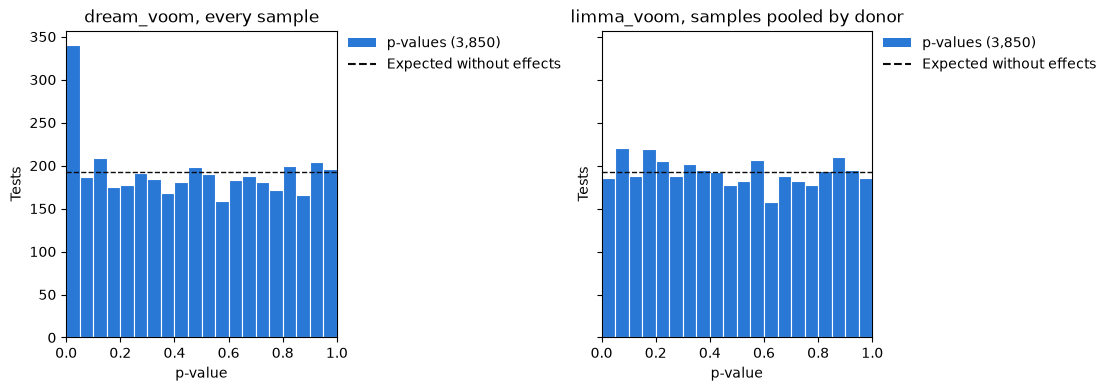

In [4]:
pooled = study.collapse_samples("donor")
pooled_design = Design(
    pooled.samples,
    "~ disease",
    levels={"disease": ["healthy", "patient"]},
    contrasts={"patient_vs_healthy": "diseasepatient"},
)
by_donor = limma_voom(pooled, pooled_design)

figure, (left, right) = plt.subplots(
    1, 2, figsize=(11, 3.8), layout="constrained", sharey=True
)
for ax, tested, title in (
    (left, result, "dream_voom, every sample"),
    (right, by_donor, "limma_voom, samples pooled by donor"),
):
    table = tested.table("Monocytes", "patient_vs_healthy")
    unchanged = disease_effect[np.searchsorted(genes, table["feature_id"])] == 0
    plot_p_values(table["p_value"][unchanged], ax=ax)
    ax.set_title(title)
    called = table["adjusted_p_value"] < 0.05
    print(
        f"{title}: {called.sum()} genes called, {(called & unchanged).sum()} of them false"
    )
plt.show()

dream_voom's p-values of the unchanged genes gather below 0.05, about 1.8 times as
many as expected there; those of the pooled profiles are uniform, and 3 of their 62
calls are false. The pooled comparison finds fewer genes, but those it finds hold.
Pooling suits a design in which every donor was sampled alike, as here; the changes
within donors are tested on every sample, where dream_voom kept their error rate.

## What drives the variation between samples

Variance partitioning fits every gene with a mixed model of every variable of the
design and reports the share of its variance that each explains [@hoffman2016], as
variancePartition does. It shows which variables dominate, and which genes follow
each. {api}`variance_partitioning` runs it on every cell type of a cube, after the
same steps as {api}`dream_voom`.

median share of a gene's variance: donor 8%, condition 43%, residuals 34%


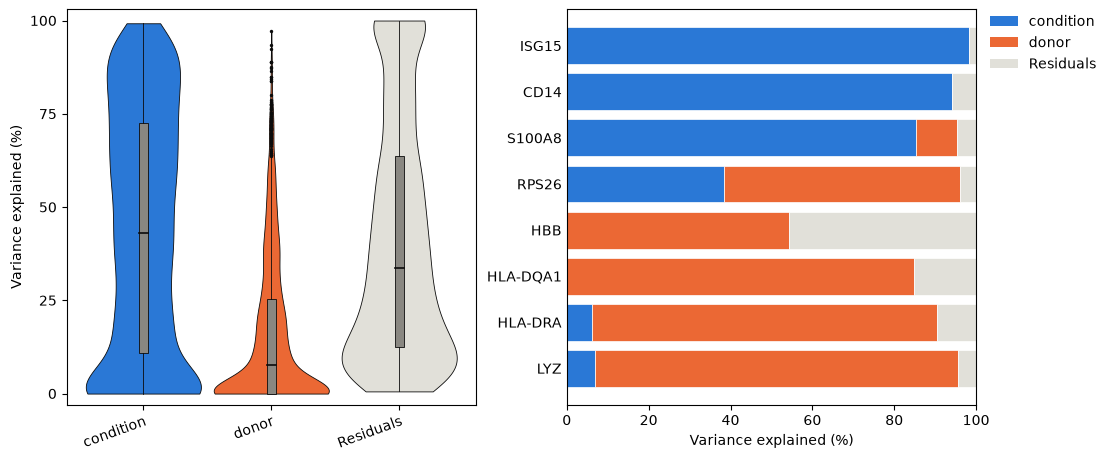

In [5]:
partition_design = Design(
    kang.samples, "~ 1", random=["(1 | donor)", "(1 | condition)"]
)
partition = variance_partitioning(kang, partition_design, groups=monocytes)
chosen = ["ISG15", "CD14", "S100A8", "RPS26", "HBB", "HLA-DQA1", "HLA-DRA", "LYZ"]

fractions = partition.table(monocytes)
shares = [f"{name} {np.median(fractions[name]):.0%}" for name in partition.variables]
print("median share of a gene's variance:", ", ".join(shares))

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
plot_variance_fractions(partition, ax=left)
plot_feature_variance_fractions(partition, chosen, ax=right)
plt.show()

The stimulation explains much of the variance of most genes, and the donors a little
of most, but the genes differ widely. ISG15 and CD14 vary almost only with the
stimulation; the HLA class II genes HLA-DQA1 and HLA-DRA, which differ between people,
and LYZ vary mostly between donors, and RPS26 with both. HBB, whose reads come from
contaminating red cells, varies between donors and between the two samples of each
donor, which the residuals hold.

## Choices

- **A fixed or a random donor effect.** With every donor in every condition and a
  question within donors, the paired design and {api}`limma_voom` are the simplest. A
  variable of the donors, such as disease, sex or age, needs the random effect and
  {api}`dream_voom`, and so do donors with unequal numbers of samples.
- **Few donors, a question between donors.** With three donors in each group,
  dream_voom's test between donors called too many genes above. When every donor was
  sampled alike, compare the profiles pooled by donor ({api}`Cube.collapse_samples`)
  with {api}`limma_voom` instead, and test the changes within donors with
  {api}`dream_voom`.
- **Degrees of freedom.** `df_method="adaptive"`, the default, uses Kenward and
  Roger's below 20 samples and Satterthwaite's from 20; `"kenward_roger"` and
  `"satterthwaite"` fix one ([Mixed models, REML and dream](../statistics/mixed_models.md)).
- **Several time points or groups.** `f_tests` asks whether anything changes among
  them; the contrasts then say what changes when.
- **What to adjust for.** A variable that explains much of the variance of many
  genes and is not the question, such as a batch, is worth a term in the design.
  [Normalization, filtering and sample quality](normalization_and_quality.ipynb)
  shows how to look for outlying samples.